# Bank Marketing Dataset — Machine Learning Models

**Target:** `deposit` (yes/no) — Binary Classification

**Models Applied:**
1. Linear Regression
2. Logistic Regression
3. Naive Bayes
4. K-Nearest Neighbors (KNN)
5. Support Vector Machine (SVM)
6. Decision Tree
7. Random Forest

## 1. Import Libraries

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

print('All libraries imported successfully!')

All libraries imported successfully!


## 2. Load and Explore Data

In [13]:
import os

if os.path.exists('/kaggle/input/bank-marketing-dataset/bank.csv'):
    df = pd.read_csv('/kaggle/input/bank-marketing-dataset/bank.csv')
elif os.path.exists('bank.csv'):
    df = pd.read_csv('bank.csv')
else:
    for root, dirs, files in os.walk('.'):
        for f in files:
            if f.endswith('.csv'):
                df = pd.read_csv(os.path.join(root, f))
                print(f'Loaded: {os.path.join(root, f)}')
                break

print(f'Shape: {df.shape}')
df.head()

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [14]:
print('=== Dataset Info ===')
df.info()
print('\n=== Missing Values ===')
print(df.isnull().sum())
print('\n=== Target Distribution ===')
print(df['deposit'].value_counts())
print(f'\nClass Balance: {df["deposit"].value_counts(normalize=True).round(3).to_dict()}')

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  deposit    45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

=== Missing Values ===
age          0
job          0
marital      0
education

In [15]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


## 3. Exploratory Data Analysis (EDA)

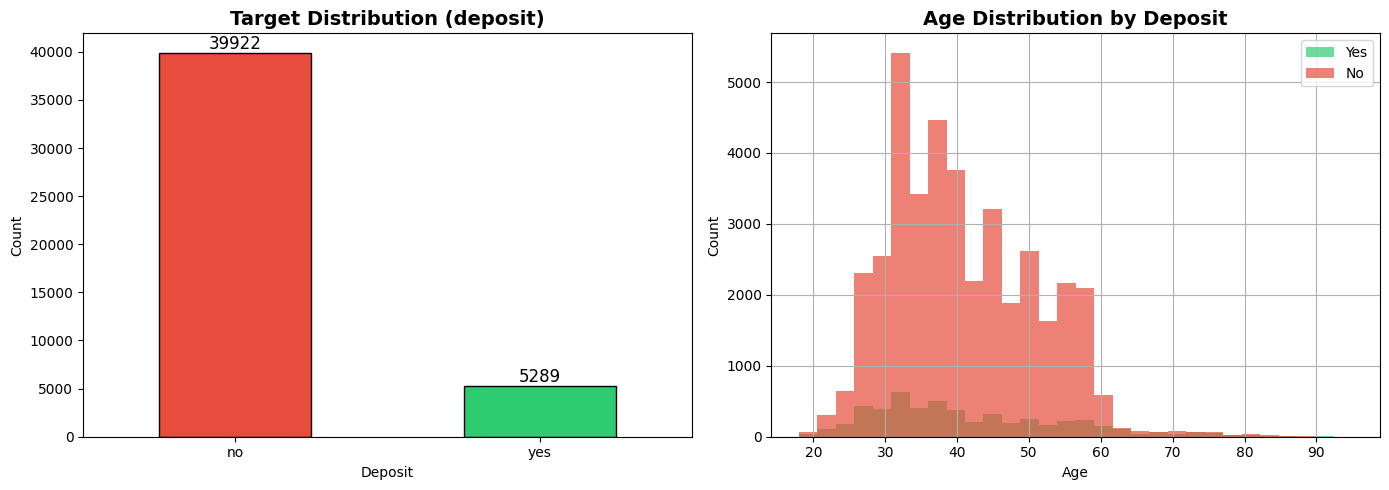

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#e74c3c', '#2ecc71']
df['deposit'].value_counts().plot(kind='bar', ax=axes[0], color=colors, edgecolor='black', rot=0)
axes[0].set_title('Target Distribution (deposit)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Deposit')
axes[0].set_ylabel('Count')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=12)

df[df['deposit']=='yes']['age'].hist(ax=axes[1], bins=30, alpha=0.7, color='#2ecc71', label='Yes')
df[df['deposit']=='no']['age'].hist(ax=axes[1], bins=30, alpha=0.7, color='#e74c3c', label='No')
axes[1].set_title('Age Distribution by Deposit', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

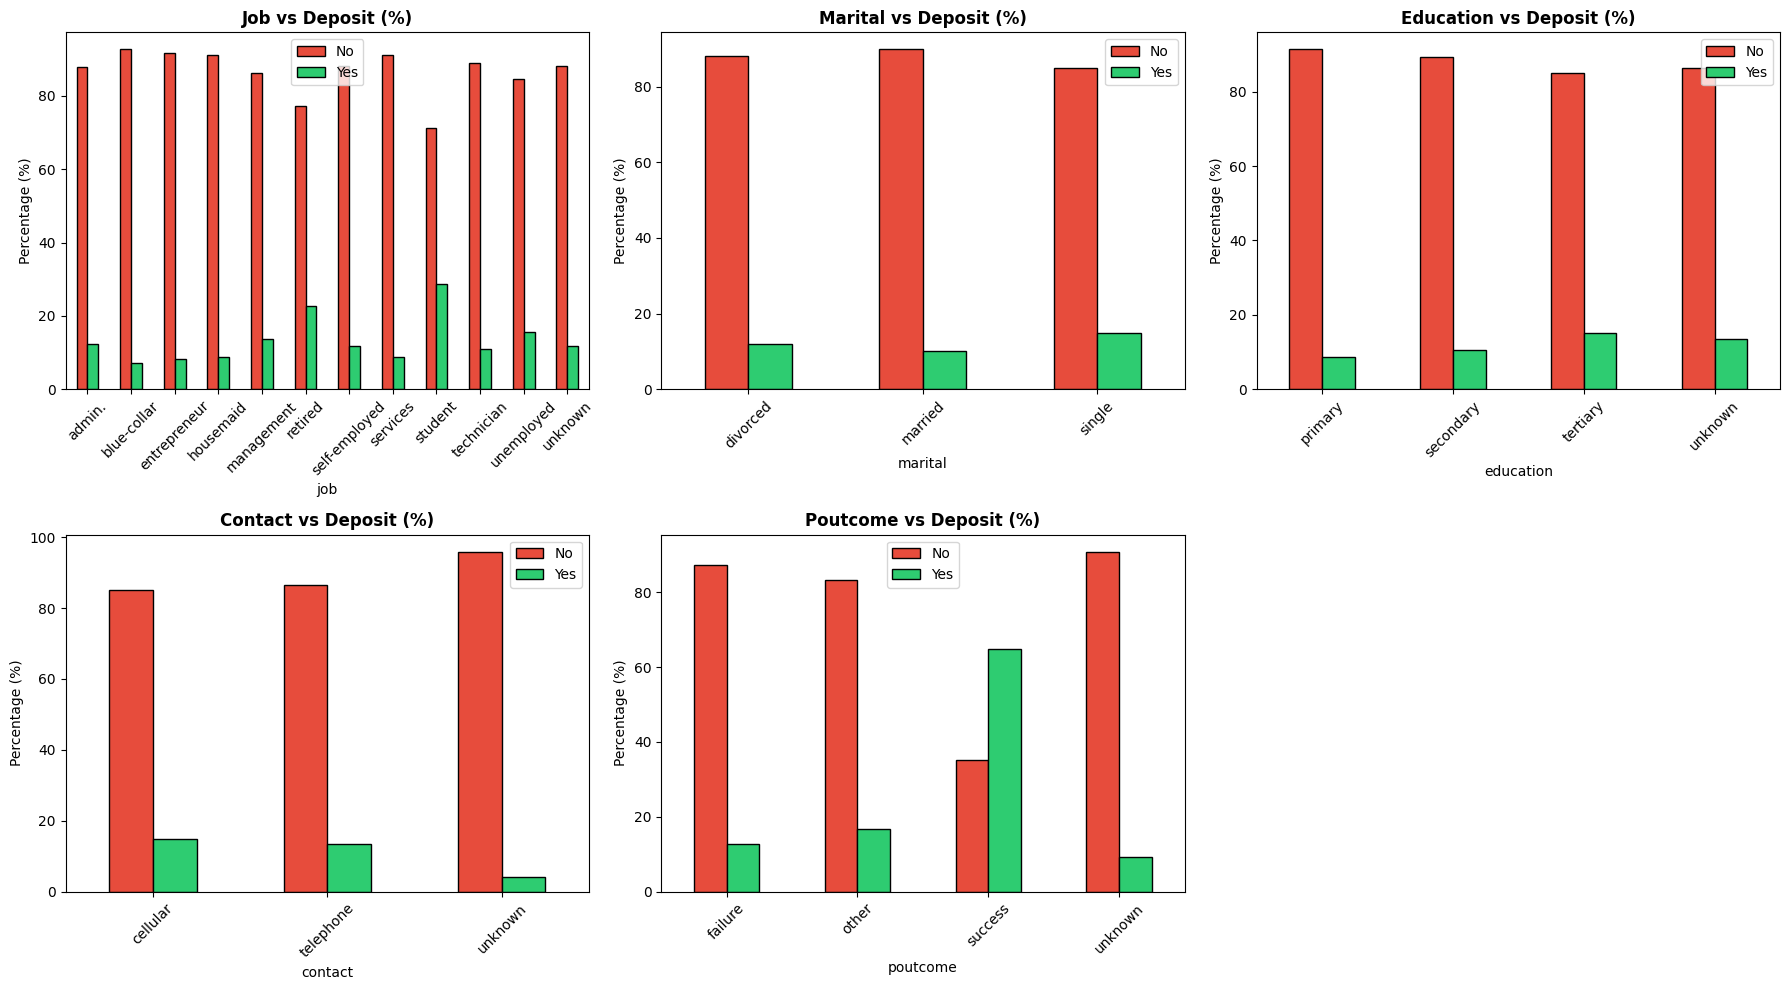

In [18]:
cat_cols = ['job', 'marital', 'education', 'contact', 'poutcome']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df[col], df['deposit'], normalize='index') * 100
    ct.plot(kind='bar', ax=axes[i], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=45)
    axes[i].set_title(f'{col.capitalize()} vs Deposit (%)', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Percentage (%)')
    axes[i].legend(['No', 'Yes'])

axes[5].set_visible(False)
plt.tight_layout()
plt.show()

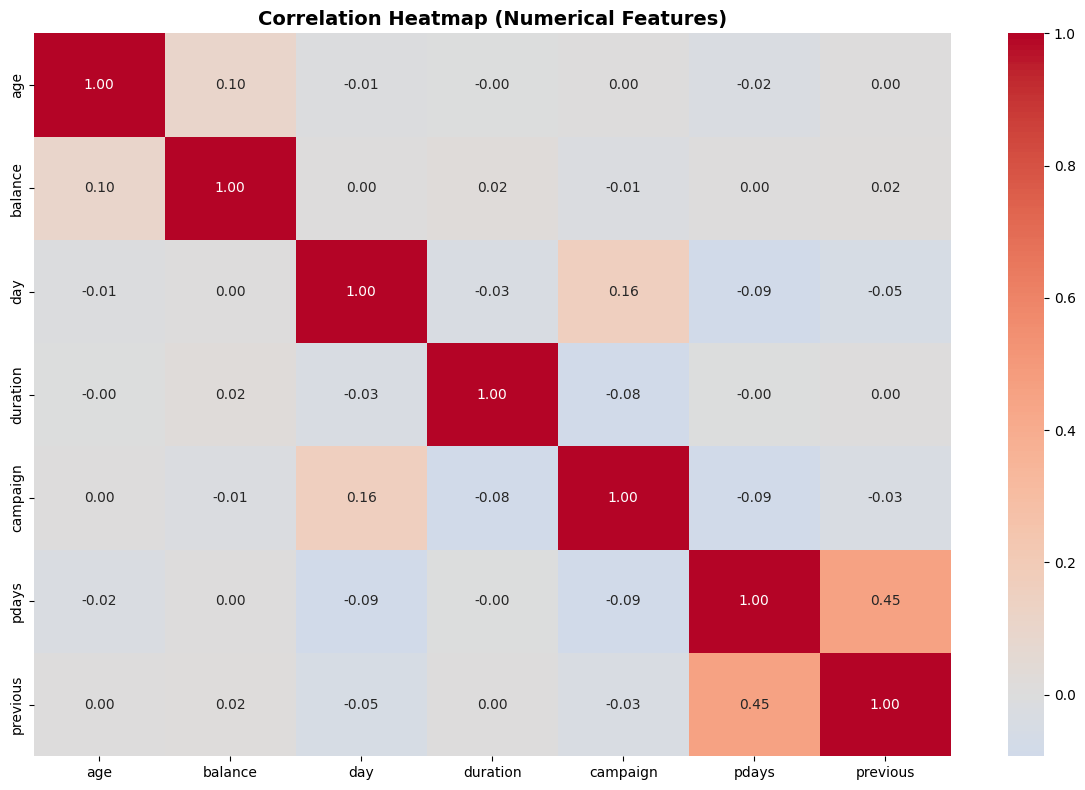

In [19]:
plt.figure(figsize=(12, 8))
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (Numerical Features)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Preprocessing

In [20]:
data = df.copy()

# Encode target
data['deposit'] = data['deposit'].map({'yes': 1, 'no': 0})

# Encode categorical columns
le = LabelEncoder()
cat_columns = data.select_dtypes(include=['object']).columns.tolist()
print(f'Categorical columns: {cat_columns}')

for col in cat_columns:
    data[col] = le.fit_transform(data[col])

print('Encoding done!')
data.head()

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Encoding done!


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1,0,3,0
1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1,0,3,0
2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1,0,3,0
4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1,0,3,0


In [21]:
X = data.drop('deposit', axis=1)
y = data['deposit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f'Training set : {X_train.shape}')
print(f'Test set     : {X_test.shape}')
print(f'Target balance in train: {pd.Series(y_train).value_counts(normalize=True).round(3).to_dict()}')

Training set : (36168, 16)
Test set     : (9043, 16)
Target balance in train: {0: 0.883, 1: 0.117}


## Helper Function — Evaluate Model

In [22]:
results = {}

def evaluate_model(name, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    roc = roc_auc_score(y_true, y_prob) if y_prob is not None else None
    results[name] = {'Accuracy': round(acc, 4), 'ROC-AUC': round(roc, 4) if roc else 'N/A'}

    print('=' * 55)
    print(f'  {name}')
    print('=' * 55)
    print(f'  Accuracy : {acc:.4f} ({acc*100:.2f}%)')
    if roc:
        print(f'  ROC-AUC  : {roc:.4f}')
    print()
    print(classification_report(y_true, y_pred, target_names=['No', 'Yes']))

    n_plots = 2 if y_prob is not None else 1
    fig, axes = plt.subplots(1, n_plots, figsize=(7 * n_plots, 5))
    if n_plots == 1:
        axes = [axes]

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
    disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
    axes[0].set_title(f'{name} — Confusion Matrix', fontweight='bold')

    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        axes[1].plot(fpr, tpr, color='#3498db', lw=2, label=f'AUC = {roc:.4f}')
        axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
        axes[1].set_xlabel('False Positive Rate')
        axes[1].set_ylabel('True Positive Rate')
        axes[1].set_title(f'{name} — ROC Curve', fontweight='bold')
        axes[1].legend(loc='lower right')

    plt.tight_layout()
    plt.show()

print('Helper function ready!')

Helper function ready!


---
## Model 1 — Linear Regression
ملاحظة: Linear Regression مش classification model بالأساس، بنطبقه على classification بـ threshold = 0.5

  Linear Regression
  Accuracy : 0.8874 (88.74%)
  ROC-AUC  : 0.8703

              precision    recall  f1-score   support

          No       0.89      0.99      0.94      7985
         Yes       0.60      0.11      0.19      1058

    accuracy                           0.89      9043
   macro avg       0.75      0.55      0.57      9043
weighted avg       0.86      0.89      0.85      9043



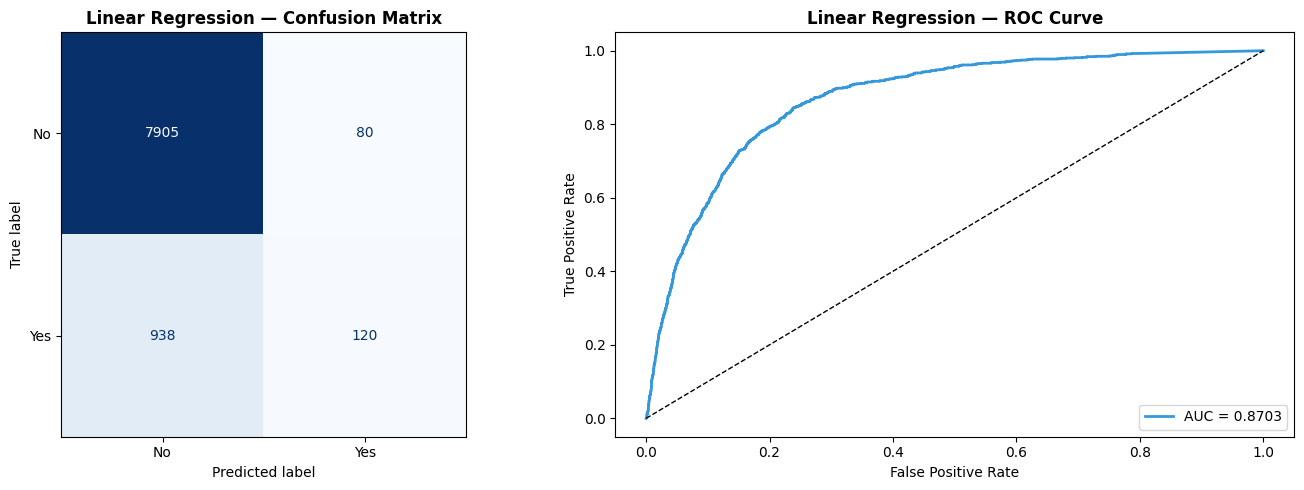

Coefficients (top 5 by absolute value):
     Feature  Coefficient
11  duration     0.125630
13     pdays     0.045973
6    housing    -0.042167
8    contact    -0.034364
15  poutcome     0.029893


In [23]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr_raw = lr.predict(X_test_scaled)
y_pred_lr = (y_pred_lr_raw >= 0.5).astype(int)
y_prob_lr = np.clip(y_pred_lr_raw, 0, 1)

evaluate_model('Linear Regression', y_test, y_pred_lr, y_prob_lr)

print('Coefficients (top 5 by absolute value):')
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': lr.coef_})
print(coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index).head())

---
## Model 2 — Logistic Regression

  Logistic Regression
  Accuracy : 0.8914 (89.14%)
  ROC-AUC  : 0.8726

              precision    recall  f1-score   support

          No       0.91      0.98      0.94      7985
         Yes       0.59      0.23      0.33      1058

    accuracy                           0.89      9043
   macro avg       0.75      0.60      0.63      9043
weighted avg       0.87      0.89      0.87      9043



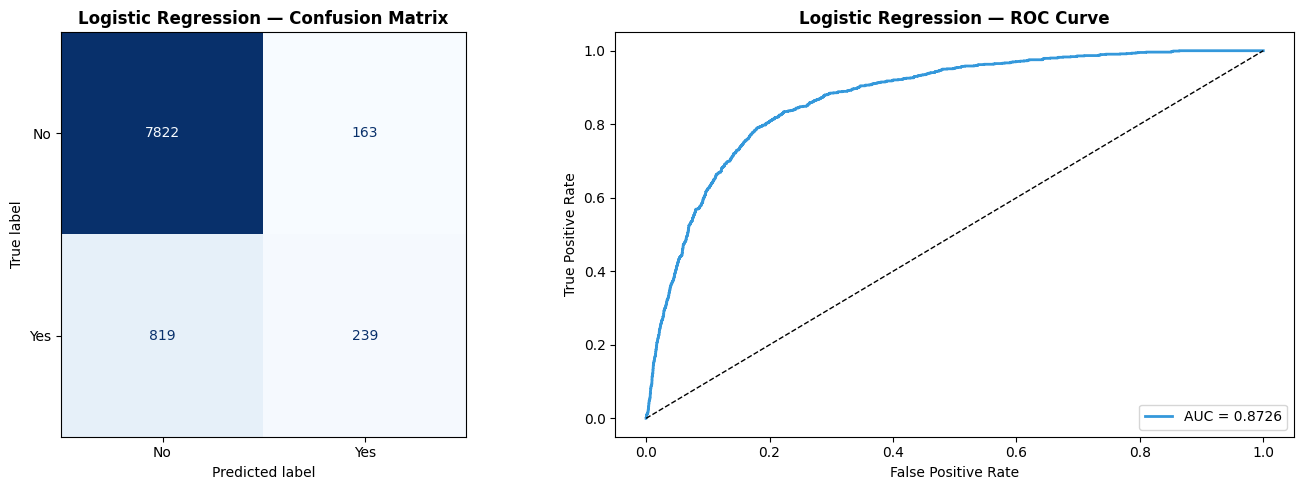

Top 5 Most Important Features (by |coefficient|):
     Feature  Coefficient
11  duration     1.028734
8    contact    -0.567330
6    housing    -0.516932
12  campaign    -0.402560
13     pdays     0.384912


In [24]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred_log = log_reg.predict(X_test_scaled)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]

evaluate_model('Logistic Regression', y_test, y_pred_log, y_prob_log)

print('Top 5 Most Important Features (by |coefficient|):')
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': log_reg.coef_[0]})
print(coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index).head())

---
## Model 3 — Naive Bayes (Gaussian)

  Naive Bayes
  Accuracy : 0.8380 (83.80%)
  ROC-AUC  : 0.8127

              precision    recall  f1-score   support

          No       0.93      0.89      0.91      7985
         Yes       0.36      0.47      0.41      1058

    accuracy                           0.84      9043
   macro avg       0.64      0.68      0.66      9043
weighted avg       0.86      0.84      0.85      9043



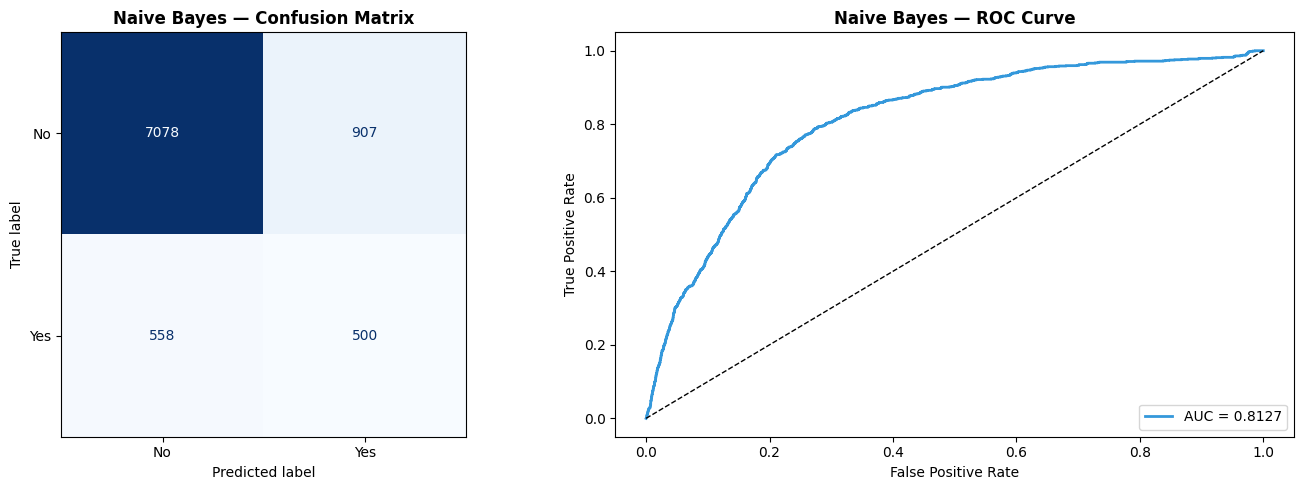

In [25]:
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

y_pred_nb = nb.predict(X_test_scaled)
y_prob_nb = nb.predict_proba(X_test_scaled)[:, 1]

evaluate_model('Naive Bayes', y_test, y_pred_nb, y_prob_nb)

---
## Model 4 — K-Nearest Neighbors (KNN)

Best K = 9 with CV Accuracy = 0.8954


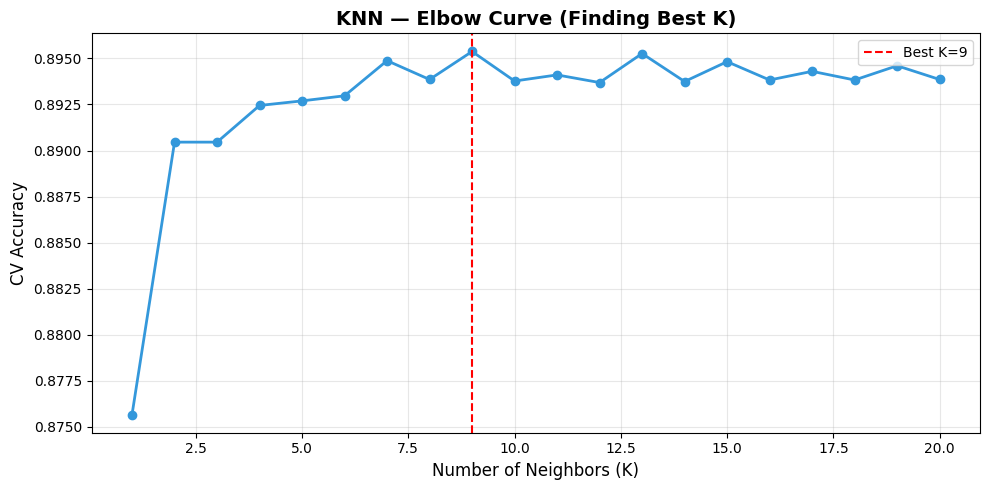

In [26]:
# Find best K using Cross-Validation
k_values = range(1, 21)
k_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring='accuracy').mean()
    k_scores.append(score)

best_k = k_values[np.argmax(k_scores)]
print(f'Best K = {best_k} with CV Accuracy = {max(k_scores):.4f}')

plt.figure(figsize=(10, 5))
plt.plot(k_values, k_scores, marker='o', color='#3498db', linewidth=2, markersize=6)
plt.axvline(x=best_k, color='red', linestyle='--', label=f'Best K={best_k}')
plt.xlabel('Number of Neighbors (K)', fontsize=12)
plt.ylabel('CV Accuracy', fontsize=12)
plt.title('KNN — Elbow Curve (Finding Best K)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

  KNN (K=9)
  Accuracy : 0.8930 (89.30%)
  ROC-AUC  : 0.8406

              precision    recall  f1-score   support

          No       0.91      0.98      0.94      7985
         Yes       0.59      0.27      0.37      1058

    accuracy                           0.89      9043
   macro avg       0.75      0.62      0.66      9043
weighted avg       0.87      0.89      0.88      9043



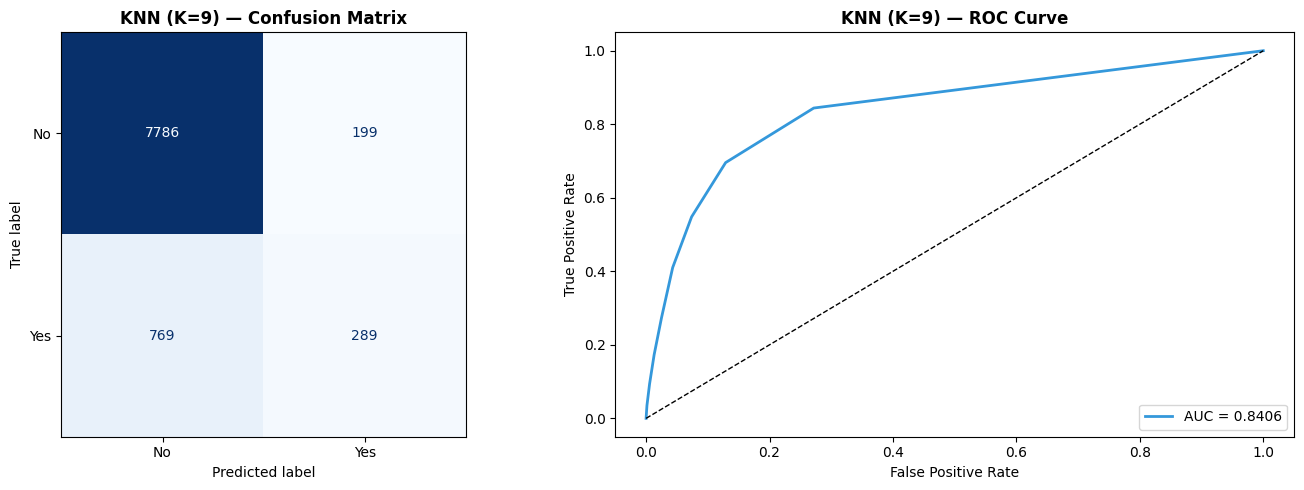

In [28]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
y_prob_knn = knn.predict_proba(X_test_scaled)[:, 1]

evaluate_model(f'KNN (K={best_k})', y_test, y_pred_knn, y_prob_knn)

---
## Model 5 — Support Vector Machine (SVM)

  SVM (RBF Kernel)
  Accuracy : 0.8972 (89.72%)
  ROC-AUC  : 0.8543

              precision    recall  f1-score   support

          No       0.91      0.98      0.94      7985
         Yes       0.65      0.26      0.37      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.62      0.66      9043
weighted avg       0.88      0.90      0.88      9043



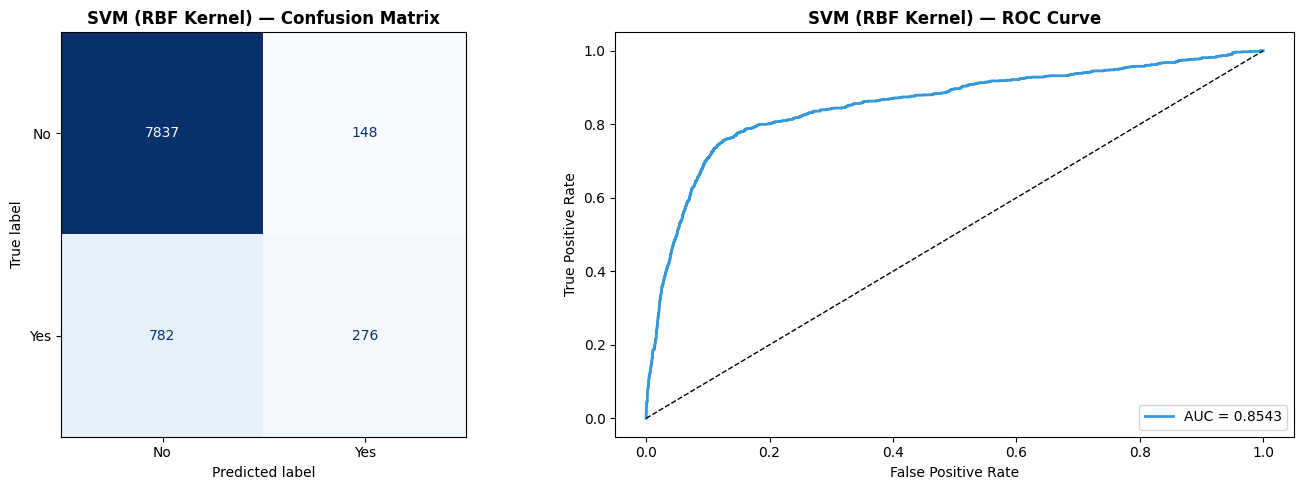

In [29]:
svm = SVC(kernel='rbf', probability=True, random_state=42, C=1.0, gamma='scale')
svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
y_prob_svm = svm.predict_proba(X_test_scaled)[:, 1]

evaluate_model('SVM (RBF Kernel)', y_test, y_pred_svm, y_prob_svm)

---
## Model 6 — Decision Tree

  Decision Tree
  Accuracy : 0.8970 (89.70%)
  ROC-AUC  : 0.8374

              precision    recall  f1-score   support

          No       0.92      0.96      0.94      7985
         Yes       0.59      0.40      0.47      1058

    accuracy                           0.90      9043
   macro avg       0.76      0.68      0.71      9043
weighted avg       0.88      0.90      0.89      9043



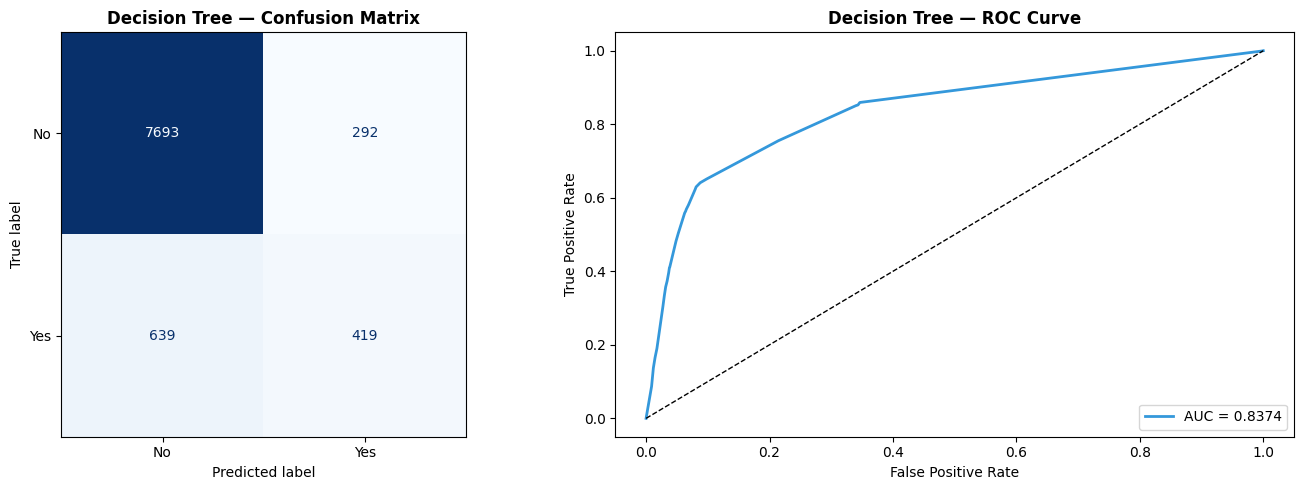

In [30]:
dt = DecisionTreeClassifier(max_depth=5, random_state=42, criterion='gini')
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

evaluate_model('Decision Tree', y_test, y_pred_dt, y_prob_dt)

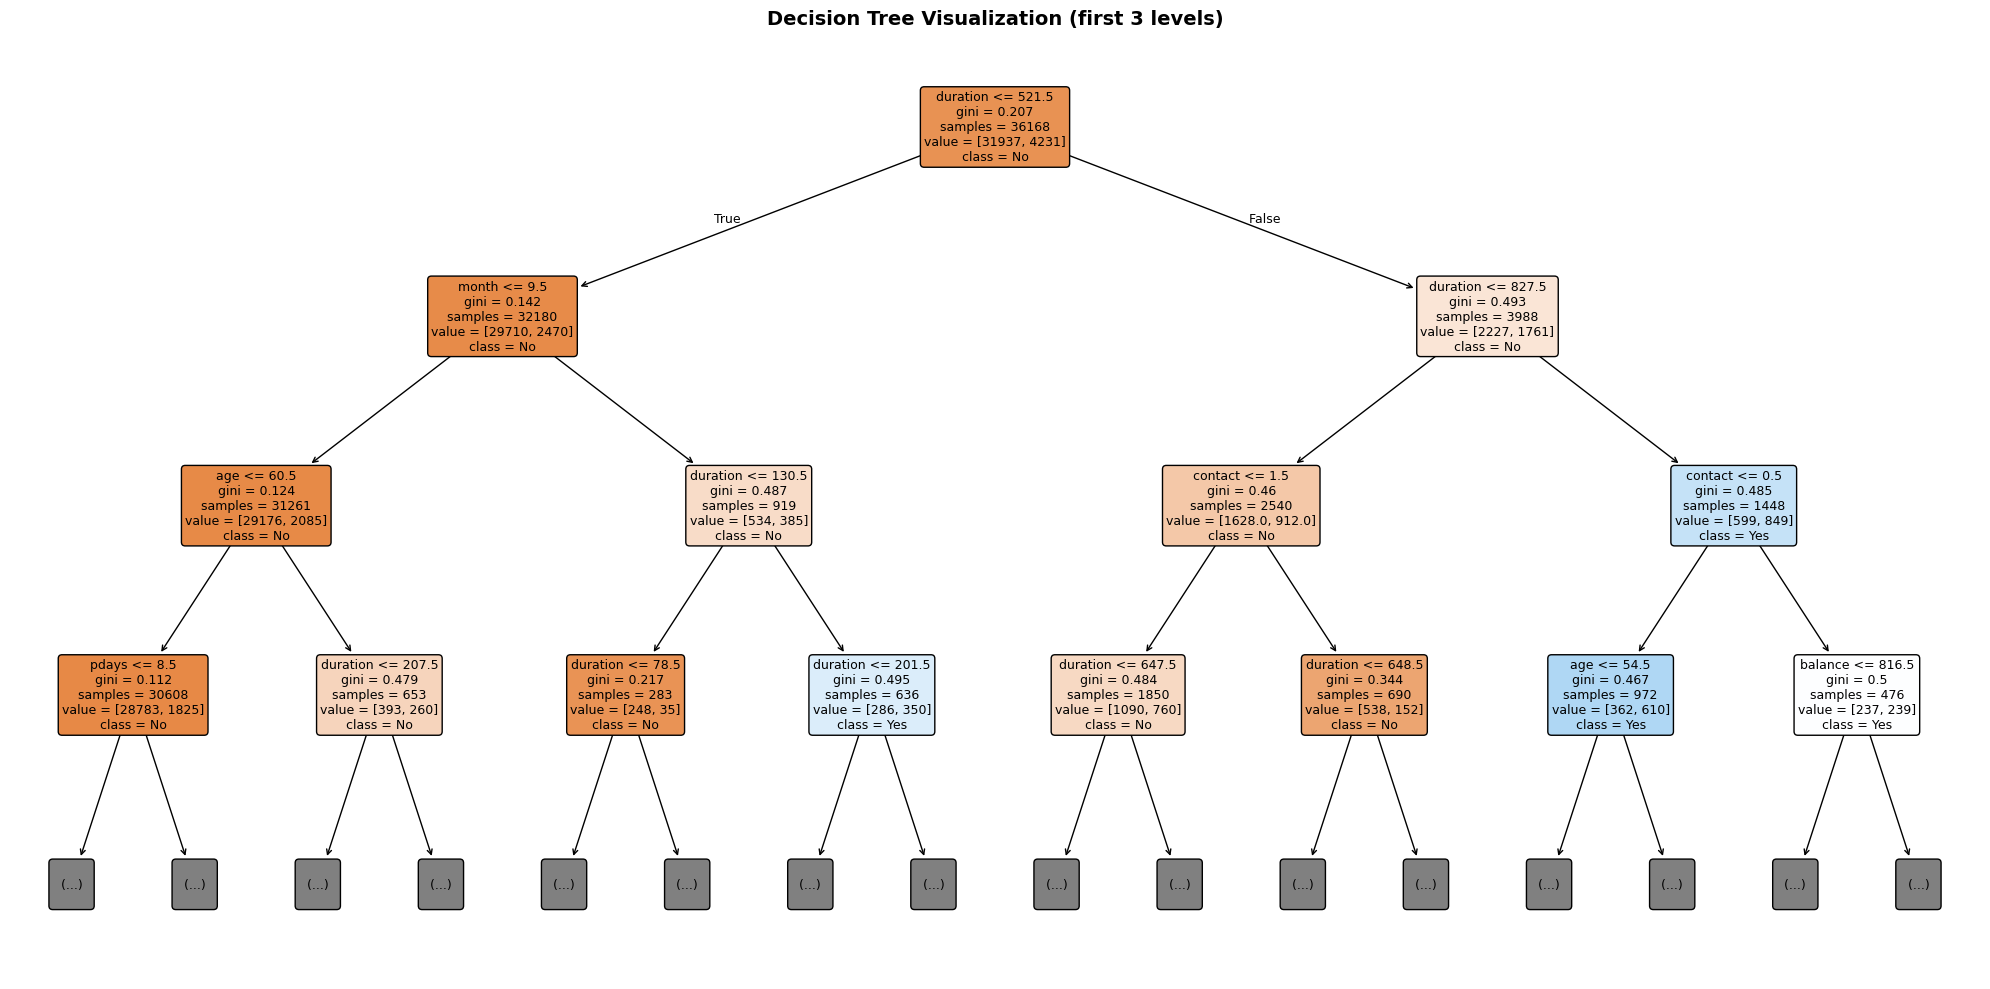

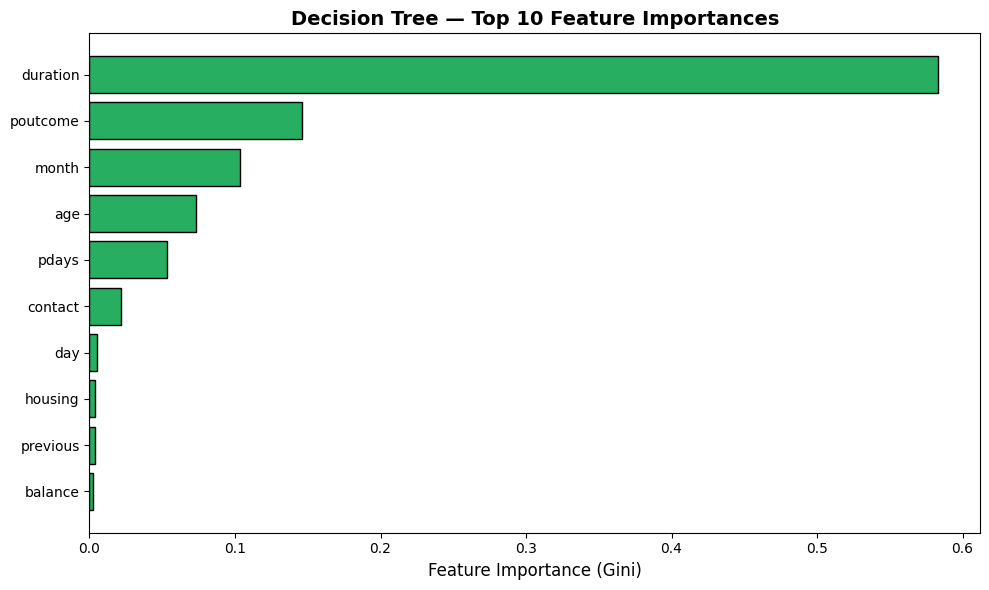

In [31]:
plt.figure(figsize=(20, 10))
plot_tree(
    dt,
    feature_names=X.columns.tolist(),
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3
)
plt.title('Decision Tree Visualization (first 3 levels)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

fi_dt = pd.DataFrame({'Feature': X.columns, 'Importance': dt.feature_importances_})
fi_dt = fi_dt.sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(fi_dt['Feature'][:10], fi_dt['Importance'][:10], color='#27ae60', edgecolor='black')
plt.gca().invert_yaxis()
plt.xlabel('Feature Importance (Gini)', fontsize=12)
plt.title('Decision Tree — Top 10 Feature Importances', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Model 7 — Random Forest

  Random Forest
  Accuracy : 0.9055 (90.55%)
  ROC-AUC  : 0.9214

              precision    recall  f1-score   support

          No       0.92      0.98      0.95      7985
         Yes       0.69      0.35      0.46      1058

    accuracy                           0.91      9043
   macro avg       0.80      0.66      0.71      9043
weighted avg       0.89      0.91      0.89      9043



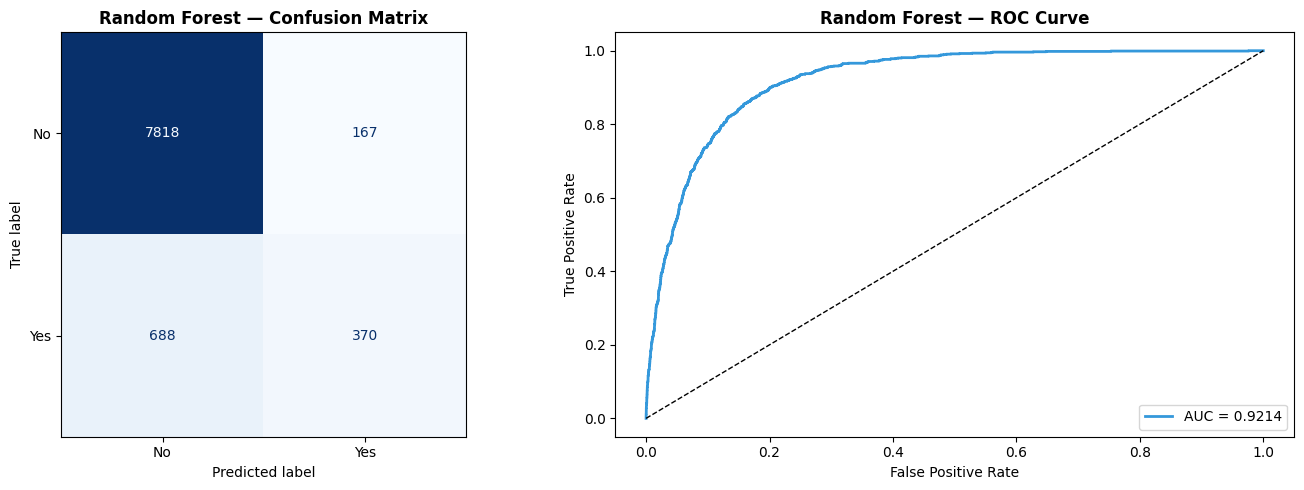

In [32]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

evaluate_model('Random Forest', y_test, y_pred_rf, y_prob_rf)

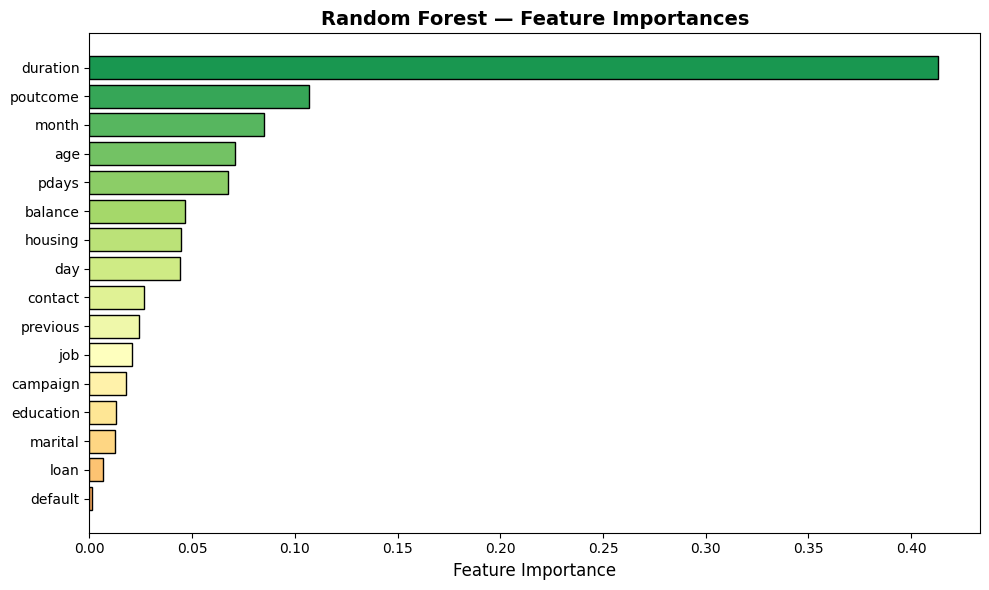

Top 5 Most Important Features:
     Feature  Importance
11  duration    0.412898
15  poutcome    0.106841
10     month    0.084906
0        age    0.071078
13     pdays    0.067471


In [33]:
fi_rf = pd.DataFrame({'Feature': X.columns, 'Importance': rf.feature_importances_})
fi_rf = fi_rf.sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
colors_bar = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(fi_rf)))
plt.barh(fi_rf['Feature'], fi_rf['Importance'], color=colors_bar[::-1], edgecolor='black')
plt.gca().invert_yaxis()
plt.xlabel('Feature Importance', fontsize=12)
plt.title('Random Forest — Feature Importances', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Top 5 Most Important Features:')
print(fi_rf.head())

---
## 8. Models Comparison — Final Results

In [35]:
results_df = pd.DataFrame(results).T.reset_index()
results_df.columns = ['Model', 'Accuracy', 'ROC-AUC']
results_df['Accuracy'] = pd.to_numeric(results_df['Accuracy'])
results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)
results_df.index += 1

print('=== Final Model Comparison ===')
print(results_df.to_string())
print(f'\nBest Model by Accuracy: {results_df.iloc[0]["Model"]} — {results_df.iloc[0]["Accuracy"]*100:.2f}%')

=== Final Model Comparison ===
                 Model  Accuracy  ROC-AUC
1        Random Forest    0.9055   0.9214
2     SVM (RBF Kernel)    0.8972   0.8543
3        Decision Tree    0.8970   0.8374
4            KNN (K=9)    0.8930   0.8406
5  Logistic Regression    0.8914   0.8726
6    Linear Regression    0.8874   0.8703
7          Naive Bayes    0.8380   0.8127

Best Model by Accuracy: Random Forest — 90.55%


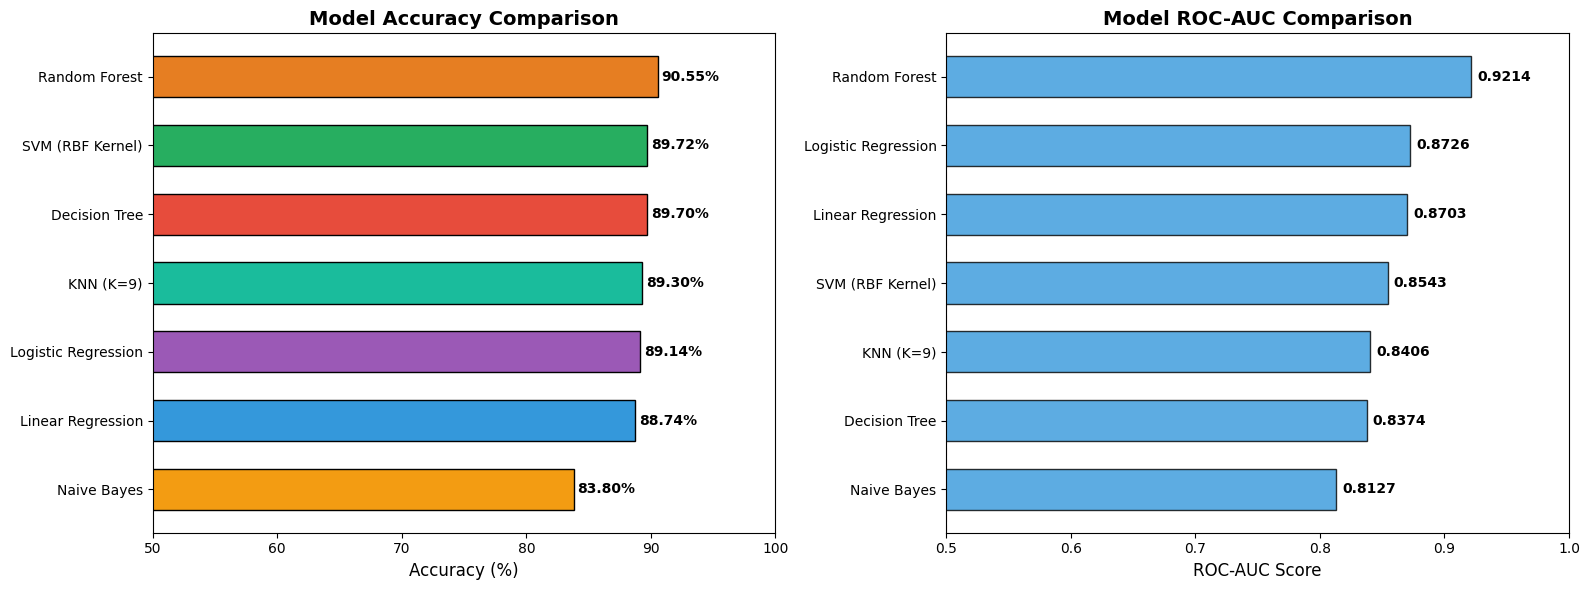

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors_models = ['#f39c12', '#3498db', '#9b59b6', '#1abc9c', '#e74c3c', '#27ae60', '#e67e22']
bars = axes[0].barh(
    results_df['Model'][::-1],
    results_df['Accuracy'][::-1] * 100,
    color=colors_models,
    edgecolor='black',
    height=0.6
)
axes[0].set_xlabel('Accuracy (%)', fontsize=12)
axes[0].set_title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlim([50, 100])
for bar, val in zip(bars, results_df['Accuracy'][::-1]):
    axes[0].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{val*100:.2f}%', va='center', fontsize=10, fontweight='bold')

roc_df = results_df[results_df['ROC-AUC'] != 'N/A'].copy()
roc_df['ROC-AUC'] = pd.to_numeric(roc_df['ROC-AUC'])
roc_df = roc_df.sort_values('ROC-AUC', ascending=True)

axes[1].barh(
    roc_df['Model'],
    roc_df['ROC-AUC'],
    color='#3498db',
    edgecolor='black',
    alpha=0.8,
    height=0.6
)
axes[1].set_xlabel('ROC-AUC Score', fontsize=12)
axes[1].set_title('Model ROC-AUC Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlim([0.5, 1.0])
axes[1].axvline(x=0.5, color='red', linestyle='--', alpha=0.5, label='Random baseline')
for i, (_, row) in enumerate(roc_df.iterrows()):
    axes[1].text(row['ROC-AUC'] + 0.005, i, f'{row["ROC-AUC"]:.4f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

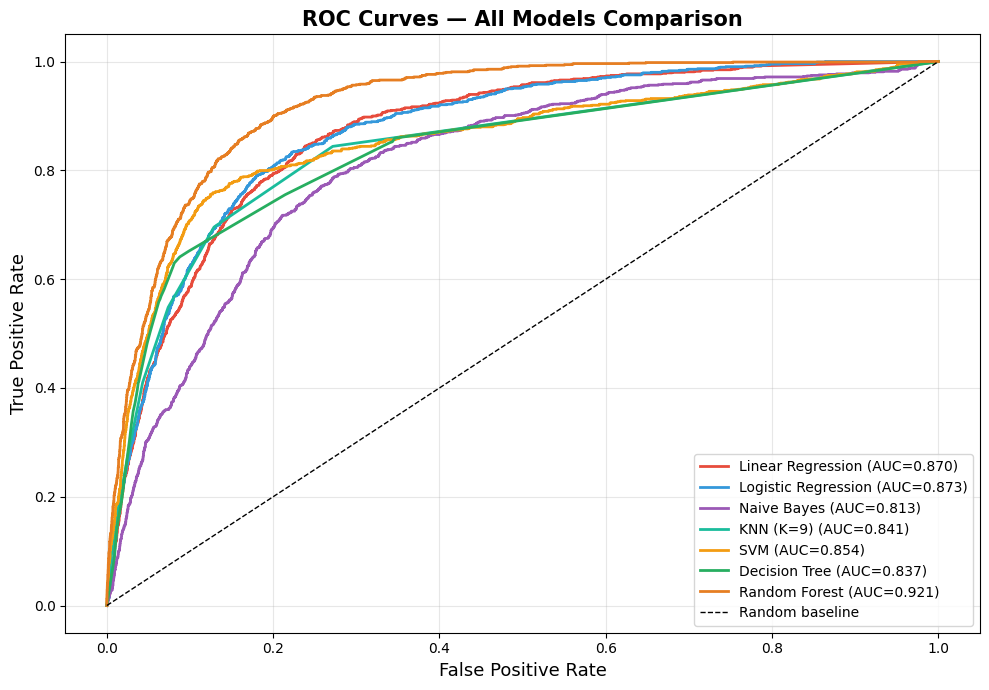

In [37]:
# All ROC Curves Together
plt.figure(figsize=(10, 7))

models_probs = {
    'Linear Regression': (y_prob_lr, '#e74c3c'),
    'Logistic Regression': (y_prob_log, '#3498db'),
    'Naive Bayes': (y_prob_nb, '#9b59b6'),
    f'KNN (K={best_k})': (y_prob_knn, '#1abc9c'),
    'SVM': (y_prob_svm, '#f39c12'),
    'Decision Tree': (y_prob_dt, '#27ae60'),
    'Random Forest': (y_prob_rf, '#e67e22'),
}

for model_name, (prob, color) in models_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, lw=2, color=color, label=f'{model_name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random baseline')
plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)
plt.title('ROC Curves — All Models Comparison', fontsize=15, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Summary

| Model | Notes |
|-------|-------|
| **Linear Regression** | مش مناسب للـ Classification بطبيعته — تم استخدامه بـ threshold=0.5 |
| **Logistic Regression** | بسيط وسريع — baseline ممتاز |
| **Naive Bayes** | سريع جداً — بيفترض استقلالية الـ features |
| **KNN** | دقيق لكن بطيء، حساس للـ scaling |
| **SVM** | قوي مع البيانات المعقدة |
| **Decision Tree** | سهل التفسير — ممكن يـ overfit بدون pruning |
| **Random Forest** | الأفضل عادةً — مقاوم للـ overfitting |